In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("data.csv")

print("Размер таблицы:", df.shape)
print(df[["student_id", "subgroup", "post_checks_per_week", "subject", "assignment", "status"]].head())
print("\nСтатусы выполнения ДЗ:")
print(df["status"].value_counts())
print("\nЗадания по подгруппам (NaN — общие для всей группы):")
print(df["assignment_subgroup"].value_counts(dropna=False))

Размер таблицы: (1118, 13)
  student_id  subgroup  post_checks_per_week                subject  \
0        S01         1                   5.4  Исследование операций   
1        S02         1                   1.2  Исследование операций   
2        S03         1                   4.9  Исследование операций   
3        S04         1                   1.0  Исследование операций   
4        S05         1                   6.7  Исследование операций   

               assignment   status  
0  Лабораторная работа №1  on_time  
1  Лабораторная работа №1     late  
2  Лабораторная работа №1  on_time  
3  Лабораторная работа №1     late  
4  Лабораторная работа №1  on_time  

Статусы выполнения ДЗ:
status
on_time          783
late             183
not_submitted    152
Name: count, dtype: int64

Задания по подгруппам (NaN — общие для всей группы):
assignment_subgroup
NaN    910
1.0    104
2.0    104
Name: count, dtype: int64


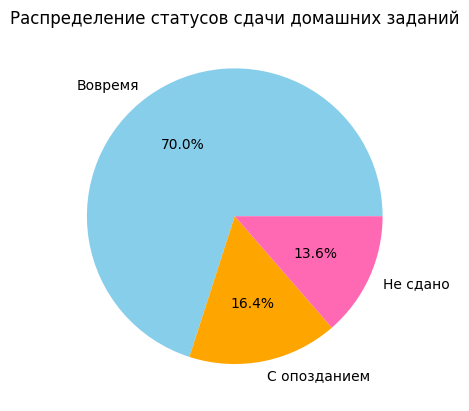

In [3]:
status_counts = df["status"].value_counts()
labels = ["Вовремя", "С опозданием", "Не сдано"]
values = [
    status_counts["on_time"],
    status_counts["late"],
    status_counts["not_submitted"],
]
colors = ["skyblue", "orange", "hotpink"]

plt.pie(values, labels=labels, colors=colors, autopct="%1.1f%%",)
plt.title("Распределение статусов сдачи домашних заданий")
plt.show()

Из 1 118 заданий вовремя сдано **783 работы (70.0%)**, с опозданием — **183 работы (16.4%)**, а **152 работы (13.6%)** не сданы совсем. Таким образом, **30% всех заданий** выполняются с нарушением сроков или теряются, что говорит о неэффективности ручного ведения одного общего поста с ДЗ.
___

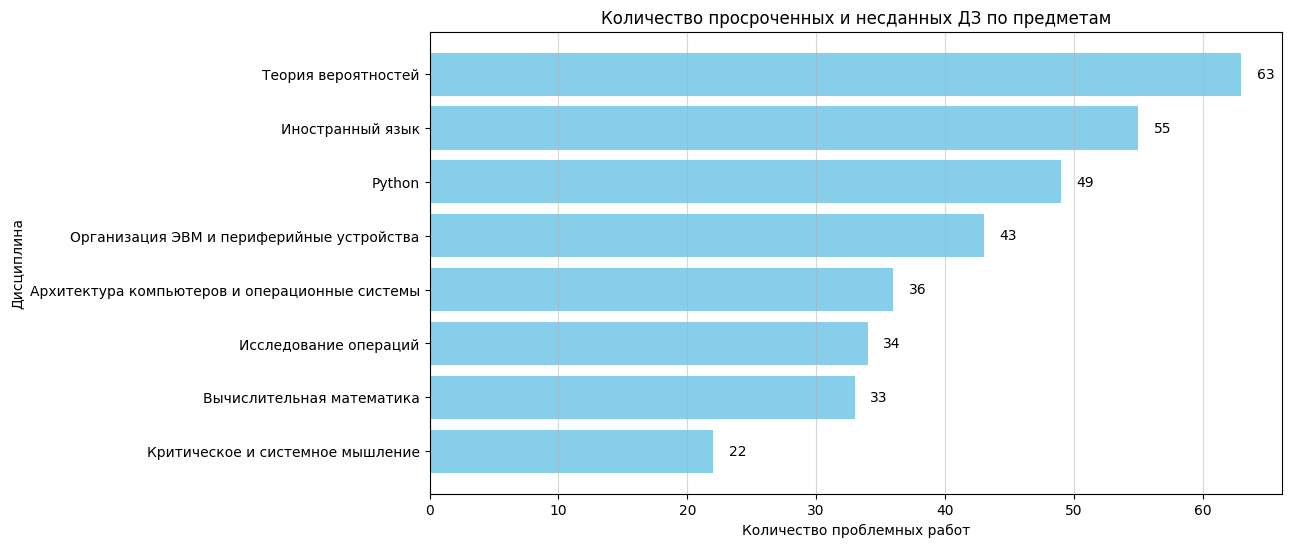

In [4]:
problem_df = df[df["status"] != "on_time"]
problem_counts = problem_df["subject"].value_counts().sort_values()

plt.figure(figsize=(11, 6))
plt.barh(problem_counts.index, problem_counts, color="skyblue")
plt.title("Количество просроченных и несданных ДЗ по предметам")
plt.xlabel("Количество проблемных работ")
plt.ylabel("Дисциплина")
plt.grid(axis="x", alpha=0.5)

for i in range(len(problem_counts)):
    label = problem_counts.index[i]
    value = problem_counts.iloc[i]
    plt.text(value + 1.2, label, f"{value}", va="center")

plt.show()

Больше всего просрочек и несдач приходится на «Теорию вероятностей» (63 работы), «Иностранный язык» (55 работ) и «Python» (49 работ), что отчасти связано с большим числом заданий по этим курсам. В целом проблемы со сроками встречаются по всем 8 дисциплинам без исключения, поэтому группе нужен единый удобный трекер дедлайнов по всем предметам.
___

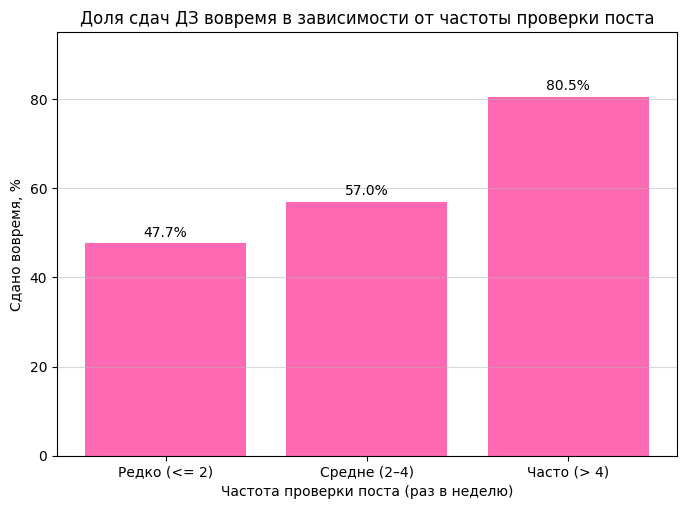

In [5]:
rare = df[df["post_checks_per_week"] <= 2]
medium = df[(df["post_checks_per_week"] > 2) & (df["post_checks_per_week"] <= 4)]
often = df[df["post_checks_per_week"] > 4]

group_names = ["Редко (<= 2)", "Средне (2–4)", "Часто (> 4)"]
on_time_pct = [
    len(rare[rare["status"] == "on_time"]) / len(rare) * 100,
    len(medium[medium["status"] == "on_time"]) / len(medium) * 100,
    len(often[often["status"] == "on_time"]) / len(often) * 100,
]

plt.figure(figsize=(8, 5.5))
plt.bar(group_names, on_time_pct, color="hotpink")
plt.title("Доля сдач ДЗ вовремя в зависимости от частоты проверки поста")
plt.xlabel("Частота проверки поста (раз в неделю)")
plt.ylabel("Сдано вовремя, %")
plt.ylim(0, 95)
plt.grid(axis="y", alpha=0.5)

for i in range(len(group_names)):
    plt.text(group_names[i], on_time_pct[i] + 1.5, f"{on_time_pct[i]:.1f}%", ha="center")

plt.show()

Студенты, которые редко заходят в общий пост (`<= 2` раз в неделю), сдают вовремя только **47.7%** работ, а **52.3%** просрочивают или не сдают. Среди тех, кто проверяет пост чаще 4 раз в неделю, вовремя сдаётся **80.5%** заданий. Это показывает, что основная причина потерь — несвоевременное получение информации, поэтому ВК-боту нужны автоматические напоминания в личные сообщения (APScheduler) и список ближайших дедлайнов.
___

Средняя доля сдач вовремя по неделям: 70.5%


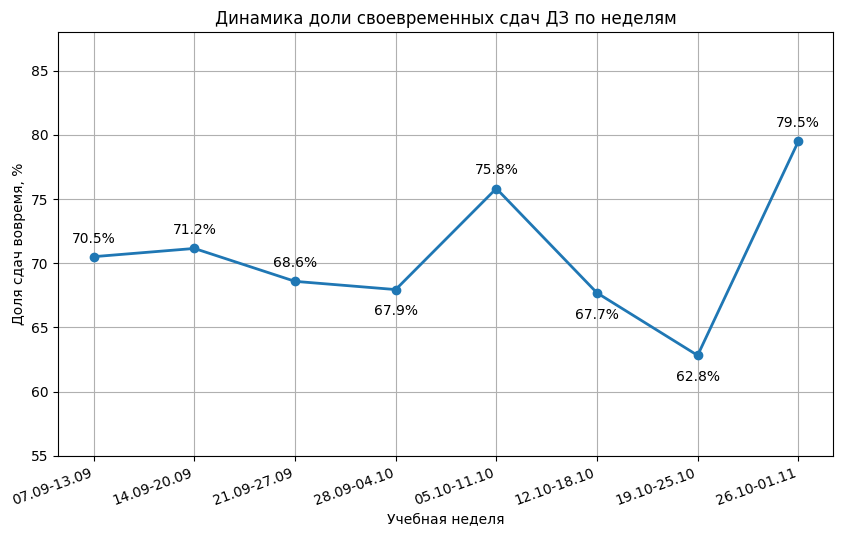

In [6]:
dates = df["deadline"].str[:10]

week_ranges = [
    ("07.09-13.09", "2026-09-07", "2026-09-13"),
    ("14.09-20.09", "2026-09-14", "2026-09-20"),
    ("21.09-27.09", "2026-09-21", "2026-09-27"),
    ("28.09-04.10", "2026-09-28", "2026-10-04"),
    ("05.10-11.10", "2026-10-05", "2026-10-11"),
    ("12.10-18.10", "2026-10-12", "2026-10-18"),
    ("19.10-25.10", "2026-10-19", "2026-10-25"),
    ("26.10-01.11", "2026-10-26", "2026-11-01"),
]

week_names = []
on_time_by_week = []

for name, start, end in week_ranges:
    part = df[(dates >= start) & (dates <= end)]
    pct = len(part[part["status"] == "on_time"]) / len(part) * 100
    week_names.append(name)
    on_time_by_week.append(pct)

print(f"Средняя доля сдач вовремя по неделям: {np.mean(on_time_by_week):.1f}%")

plt.figure(figsize=(10, 5.5))
plt.plot(week_names, on_time_by_week, marker="o", linewidth=2)
plt.title("Динамика доли своевременных сдач ДЗ по неделям")
plt.xlabel("Учебная неделя")
plt.ylabel("Доля сдач вовремя, %")
plt.ylim(55, 88)
plt.xticks(rotation=20, ha="right")
plt.grid()

for i in range(len(week_names)):
    if on_time_by_week[i] < 68:
        plt.text(week_names[i], on_time_by_week[i] - 2.0, f"{on_time_by_week[i]:.1f}%", ha="center")
    else:
        plt.text(week_names[i], on_time_by_week[i] + 1.1, f"{on_time_by_week[i]:.1f}%", ha="center")

plt.show()

На протяжении семестра доля сдач вовремя держится в районе **68%–76%**, но в загруженную неделю **19.10–25.10** опускается до **62.8%**, а к концу периода (**26.10–01.11**) при снижении числа заданий поднимается до **79.5%**.

**Итог:** анализ подтверждает полезность разрабатываемого ВК-бота. Вместо одного огромного ручного поста (где часть заданий относится только к одной подгруппе, а редкая проверка поста снижает своевременность сдач с **80.5%** до **47.7%**) студенты будут получать в боте задания с фильтрацией по своей подгруппе и автоматические напоминания о дедлайнах в личные сообщения, а староста (админ) сможет удобно добавлять и редактировать ДЗ.